<a href="https://colab.research.google.com/github/navyashreenavy/Airlines-Management/blob/main/Simple_neural_network_simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Generated Successfully
Input Shape: (100, 2)
Output Shape: (100,)
Epoch 10, Loss: 0.5759
Epoch 20, Loss: 0.4902
Epoch 30, Loss: 0.4322
Epoch 40, Loss: 0.3908
Epoch 50, Loss: 0.3597
Epoch 60, Loss: 0.3354
Epoch 70, Loss: 0.3158
Epoch 80, Loss: 0.2997
Epoch 90, Loss: 0.2861
Epoch 100, Loss: 0.2744

Training Completed!
Final Weights: [1.26061941 1.40724594]
Final Bias: -0.19232331394019123
Accuracy: 97.0 %


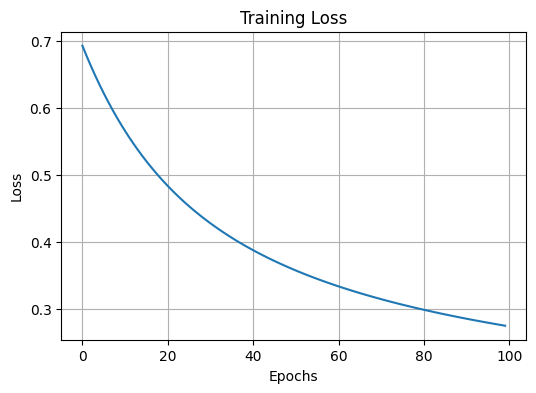

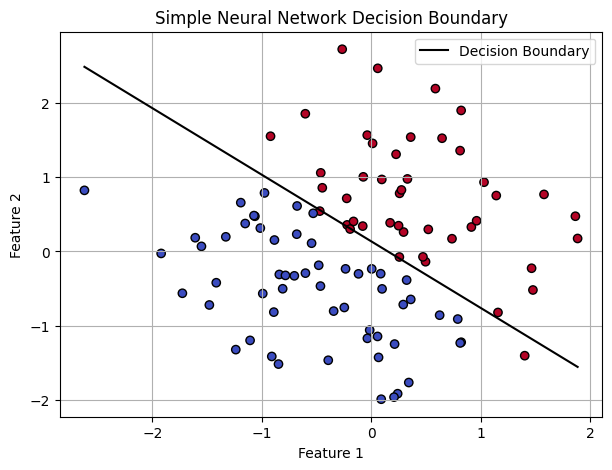


Test Predictions:
[1 2] Class: 1
[-1 -2] Class: 0


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate Dataset
np.random.seed(42)

X = np.random.randn(100, 2)

y = (X[:, 0] + X[:, 1] > 0).astype(int)

print("Dataset Generated Successfully")
print("Input Shape:", X.shape)
print("Output Shape:", y.shape)


# 2. Initialize Perceptron Parameters
weights = np.zeros(2)
bias = 0.0

learning_rate = 0.1
epochs = 100


# 3. Sigmoid Activation Function
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


# 4. Training the Neural Network
loss_history = []

for epoch in range(epochs):

    # Forward Propagation
    z = np.dot(X, weights) + bias
    predictions = sigmoid(z)

    # Calculate Loss (Binary Cross Entropy)
    epsilon = 1e-10
    loss = -np.mean(
        y * np.log(predictions + epsilon) +
        (1-y) * np.log(1-predictions + epsilon)
    )

    loss_history.append(loss)

    # Backpropagation
    dw = np.dot(X.T, (predictions - y)) / len(y)
    db = np.mean(predictions - y)

    # Update Weights using Gradient Descent
    weights -= learning_rate * dw
    bias -= learning_rate * db

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss:.4f}")


# 5. Final Predictions
final_predictions = sigmoid(np.dot(X, weights) + bias)
predicted_classes = (final_predictions >= 0.5).astype(int)

accuracy = np.mean(predicted_classes == y) * 100

print("\nTraining Completed!")
print("Final Weights:", weights)
print("Final Bias:", bias)
print("Accuracy:", accuracy, "%")


# 6. Visualize Training Loss
plt.figure(figsize=(6, 4))
plt.plot(loss_history)
plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid()
plt.show()


# 7. Visualize Decision Boundary
plt.figure(figsize=(7, 5))

plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm',
            edgecolors='black')

x_values = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)

if abs(weights[1]) > 1e-10:
    y_values = -(weights[0] * x_values + bias) / weights[1]
    plt.plot(x_values, y_values, 'k-', label="Decision Boundary")

plt.title("Simple Neural Network Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid()
plt.show()


# 8. Test New Input
test_data = np.array([[1, 2], [-1, -2]])

test_predictions = sigmoid(np.dot(test_data, weights) + bias)

print("\nTest Predictions:")
for i, prediction in enumerate(test_predictions):
    print(test_data[i], "Class:", int(prediction >= 0.5))